# Yandex Books Project

**Testing the Hypothesis on Average User Active Time Across Cities**

> **Note:** This is an educational project completed as part of a professional retraining program.

---

**Project Purpose**

The primary objective of this project is to test the hypothesis that Yandex Books users from Saint Petersburg spend, on average, more time reading and listening to books in the app than users from Moscow.

---

**Project Objectives**

1. Check groups for overlap and remove duplicate records from the dataset, if present.
2. Verify the comparability of Groups A and B, specifically evaluating their sample sizes, distributions, and summary statistics.
3. Preprocess and clean the data for downstream analytical tasks.
4. Conduct statistical hypothesis testing by selecting an appropriate significance level and a suitable statistical test.
5. Evaluate the test results and prepare an analytical summary memo.

---

**Table of Contents**

1. Data Loading, Description, and Initial Exploration
2. Data Preprocessing
   - Handling duplicates and cross-group overlaps
   - Group comparability verification
   - Data cleaning and outlier treatment
3. Statistical Hypothesis Testing
   - Formulating hypotheses
   - Selecting the significance level and test type
   - Conducting Welch's t-test
4. Analytical Summary Memo

In [1]:
#Import the necessary libraries 
import pandas as pd
import statistics
import matplotlib.pyplot as plt
from scipy import stats as st

## Data Loading, Description, and Initial Exploration

### Data Description
The data was collected and provided by the Yandex Books team. This analysis utilizes a single dataset, `yandex_knigi_data.csv`, with the following fields: 

`Unnamed: 0` — row index;

`city` — user location: Moscow or Saint Petersburg;

`puid` — unique user identifier;

`hours` — total time spent reading or listening (in hours).

### Data Loading and Initial Exploration

In [2]:
#Load the data
df = pd.read_csv('datasets/yandex_knigi_data.csv') 
#Display 5 random rows
display(df.sample(5)) 
#Display rows and fields info
df.shape

,Unnamed: 0,city,puid,hours
127,127,Москва,9623286,0.115000
7796,7796,Санкт-Петербург,1154320788,9.831779
1539,1539,Москва,309104707,0.000028
2876,2876,Москва,786476903,26.827222
2190,2190,Москва,531674667,0.789283


(8784, 4)

The dataset consists of 4 columns and 8,784 rows. Each row represents a unique user, including their geographic location (city) and total reading or listening duration in hours. The `Unnamed: 0` column contains row indices and is an artifact from saving the file. Since Python's `pandas` environment automatically generates its own zero-based index upon file ingestion, this redundant column will be dropped.

## Data Preprocessing

### Handling duplicates and cross-group overlaps

In [3]:
#Check for duplicate user IDs (puids) across the dataset
print(f"Number of duplicated IDs: {(df.duplicated(subset = ['puid'])).sum()}.")
df_duplicates = df[df.duplicated(subset = ['puid'], keep = False) == True]
#Sort the duplicate records by user ID to inspect overlapping rows sequentially
df_duplicates.sort_values(by = ['puid'])

Number of duplicated IDs: 244.


,Unnamed: 0,city,puid,hours
6247,6247,Санкт-Петербург,2637041,3.883926
35,35,Москва,2637041,10.317371
134,134,Москва,9979490,32.415573
6274,6274,Санкт-Петербург,9979490,1.302997
145,145,Москва,10597984,42.931506
...,...,...,...,...
8773,8773,Санкт-Петербург,1130000020425037,2.386944
6202,6202,Москва,1130000023864516,142.830085
8775,8775,Санкт-Петербург,1130000023864516,14.384722
8779,8779,Санкт-Петербург,1130000028554332,4.107774


Some users were recorded in both cities, leading to cross-group overlap and potential distortion of the test results. The users' data must be removed.

In [4]:
#Remove the overlapping users' data
df_cleaned = df.drop_duplicates(subset = ['puid'], keep = False)

print(f"During data cleaning, {df.shape[0] - df_cleaned.shape[0]} rows were removed, representing \
{round((df.duplicated(subset = ['puid'])).sum()/df.shape[0]*100, 2)}% of the total dataset.")

During data cleaning, 488 rows were removed, representing 2.78% of the total dataset.


### Group comparability verification
Evaluation of sample sizes, distributions, and summary statistics

In [5]:
#Check sample size
cities = df_cleaned.groupby('city', as_index=False).agg({'puid':'count', 'hours':'sum'}).round({'hours': 2})
display(cities)

#Check comparability
difference_users = round(cities.iloc[0, 1]/cities.iloc[1, 1], 2)
difference_hours = round(cities.iloc[0, 2]/cities.iloc[1, 2], 2)
print(f"User volume in Moscow is {difference_users} times higher than in Saint Petersburg, with reading and listening duration \
{difference_hours} times longer.")

,city,puid,hours
0,Москва,5990,64980.67
1,Санкт-Петербург,2306,25975.78


User volume in Moscow is 2.6 times higher than in Saint Petersburg, with reading and listening duration 2.5 times longer.


In [6]:
#Examine the distribution of reading and listening hours
stats = df_cleaned.groupby('city')['hours'].describe().T
stats

city,Москва,Санкт-Петербург
count,5990.000000,2306.000000
mean,10.848192,11.264433
std,36.925622,39.831755
min,0.000022,0.000025
25%,0.057042,0.060173
50%,0.888232,0.875355
75%,5.933439,6.138424
max,857.209373,978.764775


In [7]:
#Split the data by city to create visualizations
moscow_data = df_cleaned[df_cleaned['city'] == 'Москва']
spb_data = df_cleaned[df_cleaned['city'] == 'Санкт-Петербург']

#Data for the box plot
data_to_plot = [moscow_data['hours'], spb_data['hours']]

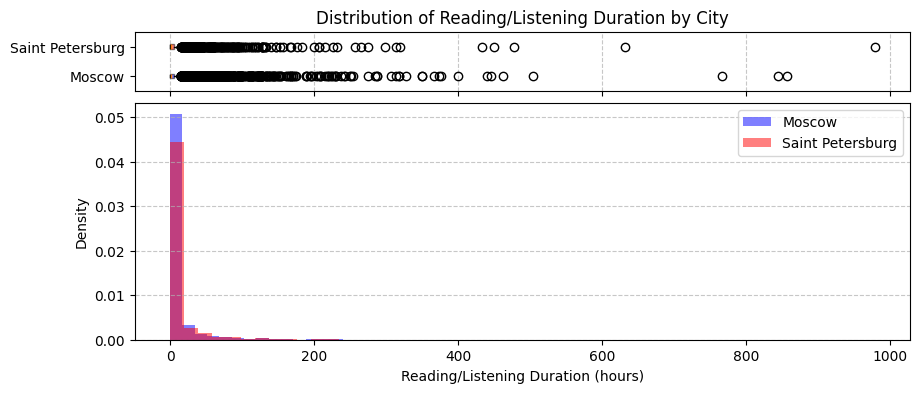

In [8]:
# Create a 2-level visualization
fig, (ax_box, ax_hist) = plt.subplots(
    2, 1, 
    figsize=(10, 4), 
    sharex=True, 
    gridspec_kw={'height_ratios': [0.2, 0.8]}
)

# 1. Top plot (Box plots)
bp = ax_box.boxplot(data_to_plot, vert=False, tick_labels=['Moscow', 'Saint Petersburg'], patch_artist=True)
# Apply the same colors to the box plots as the histograms
colors = ['b', 'r']
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.5)

ax_box.set_title('Distribution of Reading/Listening Duration by City')
ax_box.grid(axis='x', linestyle='--', alpha=0.7)
ax_box.tick_params(axis='x', labelbottom=False)  # Hide top X-axis labels

# 2. Bottom plot (Histograms)
moscow_data['hours'].plot(kind='hist', label='Moscow', bins=50, alpha=0.5, color='b', density=True, ax=ax_hist)
spb_data['hours'].plot(kind='hist', label='Saint Petersburg', bins=50, alpha=0.5, color='r', density=True, ax=ax_hist)

ax_hist.set_xlabel('Reading/Listening Duration (hours)')
ax_hist.set_ylabel('Density')
ax_hist.grid(axis='y', linestyle='--', alpha=0.7)
ax_hist.legend()

# Reduce spacing between subplots
plt.subplots_adjust(hspace=0.08)

plt.show()

The heavy right tail hampers the evaluation of the standard distribution range, so an additional visualization excluding the tail will be plotted.

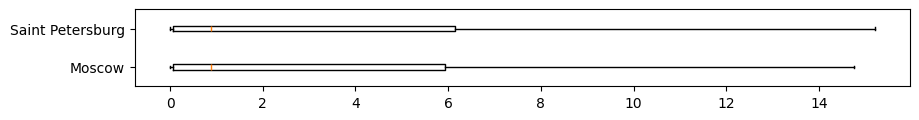

In [9]:
plt.figure(figsize=(10, 1))
bp = plt.boxplot(data_to_plot, tick_labels=['Moscow', 'Saint Petersburg'], vert = False, showfliers = False)
plt.show()

Both cities exhibit a substantial discrepancy between the median and mean values (0.89 hours vs. 10.85 hours in Moscow; 0.88 hours vs. 11.26 hours in Saint Petersburg), indicating heavy right-tail outliers. The standard deviation is large and nearly identical across groups: 36.93 in Moscow and 39.83 in Saint Petersburg.<br><br>

**Key takeaways:**<br>
- Distributions in both groups are heavily right-skewed with significant outliers.
- Applying a standard Student's t-test may yield skewed results. The heaviest outliers should be removed, followed by Welch's t-test.

### Data cleaning and outlier treatment

In [10]:
# Check quantiles from 90% to 99.9% to determine the cutoff value
quantiles = [0.90, 0.95, 0.97, 0.98, 0.99, 0.995, 0.999]

print("Moscow:")
print(moscow_data['hours'].quantile(quantiles))

print("\nSt. Petersburg:")
print(spb_data['hours'].quantile(quantiles))

Moscow:
0.900     24.271757
0.950     54.929483
0.970     83.201873
0.980    112.019630
0.990    154.688119
0.995    228.838268
0.999    440.440324
Name: hours, dtype: float64

St. Petersburg:
0.900     28.070483
0.950     56.545642
0.970     81.399764
0.980    102.444175
0.990    146.847159
0.995    229.067649
0.999    469.177630
Name: hours, dtype: float64


Activity growth remains relatively gradual up to the 90th–95th percentiles (a 5% shift adds ~25–30 hours). Between the 98th and 99th percentiles, acceleration increases noticeably (jumping from 102–112 to 146–154 hours, or +40 hours over a 1% interval). Beyond the 99th percentile, activity surges dramatically:
- 99.0th percentile $\rightarrow$ ~150 hours
- 99.5th percentile $\rightarrow$ ~229 hours (+79 hours across just 0.5%)
- 99.9th percentile $\rightarrow$ ~440–470 hours
- Maximum values $\rightarrow$ 857–978 hours

To address this, extreme values are to be **capped at the 98th percentile**. This preserves information from the high-engagement user segment while stabilizing core summary metrics (mean, standard deviation) and streamlining the interpretation of downstream statistical tests.

In [11]:
#Identify the 98th percentile threshold for each city
cutoff_msk = moscow_data['hours'].quantile(0.98)
cutoff_spb = spb_data['hours'].quantile(0.98)
print(f'Outlier cutoff threshold for Moscow: {cutoff_msk:.2f} hours; for Saint Petersburg: {cutoff_spb:.2f} hours.')

Outlier cutoff threshold for Moscow: 112.02 hours; for Saint Petersburg: 102.44 hours.


In [12]:
#Cutting off values greater than the cutoff value
moscow_data = moscow_data[moscow_data['hours']<cutoff_msk]
spb_data = spb_data[spb_data['hours']<cutoff_spb]

## Statistical Hypothesis Testing

### Formulating hypotheses
Null Hypothesis ($H_0$): $\mu_{\text{SPb}} \le \mu_{\text{Moscow}}$  
Average user active time in Saint Petersburg is not greater than in Moscow.

Alternative Hypothesis ($H_1$): $\mu_{\text{SPb}} > \mu_{\text{Moscow}}$  
Average user active time in Saint Petersburg is significantly greater than in Moscow.

### Selecting the significance level and test type
A standard industry significance level was adopted for this experiment: **$\alpha = 0.05$**.  
To test the hypothesis, a **one-tailed Welch's t-test** was performed, as a classic Student's t-test could yield misleading results due to distributional skew and remaining tail variance.

### Conducting Welch's t-test

In [13]:
#Perform a one-tailed Welch's t-test comparing Moscow vs Saint Petersburg
alpha = 0.05
t_results = st.ttest_ind(moscow_data['hours'], spb_data['hours'], equal_var=False, alternative='less')

if t_results.pvalue <= alpha:
    print(f'Calculated p-value ({t_results.pvalue:.2f}) is less than critical alpha ({alpha}). Rejecting H0 in favor of H1.')
else:
    print(f'Calculated p-value ({t_results.pvalue:.2f}) exceeds critical alpha ({alpha}). Failed to reject H0.')

Calculated p-value (0.26) exceeds critical alpha (0.05). Failed to reject H0.


## Analytical Summary Memo

To test whether Saint Petersburg users spend significantly more time reading or listening to books in the app compared to Moscow users, a Welch's t-test was conducted for unequal variances and sample sizes. This choice was driven by differences in group size and metric distribution characteristics.

The resulting test statistic yielded a **$p$-value of 0.26** at a significance level of **$\alpha = 0.05$**, providing **insufficient evidence to reject the null hypothesis** of no statistically significant difference in active duration between the two groups.

Despite the absolute mean differences observed (average reading/listening duration was 10.85 hours in Moscow vs. 11.26 hours in Saint Petersburg), the failure to reject the null hypothesis can be attributed to:

1. **High Data Variance:**
   The standard deviation in both groups (around 37–40 hours) exceeds the sample means (10.8–11.2 hours) severalfold. Due to this immense dispersion, the observed difference in means (~25 minutes) is statistically indistinguishable from random noise.
2. **Homogeneous User Cohorts:**
   Moscow and Saint Petersburg are the two largest metropolitan hubs with highly comparable lifestyles, daily routines, and digital service adoption. Users in both cities likely exhibit matching consumption habits (e.g., listening during commutes or daily chores), leading to virtually identical app engagement patterns.